# TDCS: separate multiscale sensor experiment

## tl;dr

DeFOG's reported **0.817 OOF mAP** remains the retained DeFOG experiment.
This notebook evaluates a separate TDCS model on the same 815 recordings,
61 subjects and five subject folds used by the earlier TDCS pipeline.


The separate sensor model achieved **0.3642 TDCS OOF mAP**, versus **0.3512** for the previous TDCS blend (change **+0.0130**). The recorded decision is: retain as a separate candidate. Class AP: Turn 0.7161 → 0.7884; StartHesitation 0.1868 → 0.1530; Walking 0.1506 → 0.1513.

A preliminary attempt to tune the saved TDCS model blend improved StartHesitation
and Turn but reduced Walking: pooled mAP fell from 0.3512 to 0.3460. It was
rejected. This experiment instead fits a new sensor model with settings fixed
before evaluation. Scores in this notebook are local TDCS validation scores.

## Context & Methods

Three independent histogram gradient boosting classifiers predict StartHesitation,
Turn and Walking. Each receives accelerometer features from 0.5-, 2- and 8-second
windows: amplitude, variation, range, first differences, axis correlations,
frequency-band energy and recording position. These classifiers can learn a
different feature combination for each target.

The settings are fixed: 220 boosting iterations, 31 leaves, learning rate 0.07,
capped square-root positive weighting, and no random-row early stopping.
Training uses one label every 32 native rows plus the final row. Predictions
are interpolated within each recording and evaluated on **every native row**.
Average precision is calculated over all TDCS rows for each target, then averaged
over the three targets. Fold scores describe variation; their mean is not the
pooled competition-style metric.

### Key Assumptions

- The frozen subject assignment matches the earlier TDCS experiment. The public
  example's subject `4dc2f8` is excluded, leaving exactly 815 recordings.
- Normalization and centered filters use the full recording. This is offline
  detection; the features do not support a causal, real-time claim.
- Subject IDs define the folds but are never model features. Event intervals,
  task labels, other targets and clinical metadata are never input features.
- Each held-out subject's labels are used only for evaluation. A later search
  over architectures using these results would require fresh validation to
  estimate the final selected model's generalization.

The earlier post-processing search was only second-stage cross-fitting. It was
not fully nested validation because other folds' base models may have trained
on the outer-fold subjects. It remains an exploratory, rejected result.

## Data

Run locally from `D:/Dissertation`, or attach **Parkinson's Freezing of Gait
Prediction** as a Kaggle notebook input. Nested Kaggle mounts are discovered
automatically. This notebook needs only the raw TDCS training CSVs and
`tdcsfog_metadata.csv`; its frozen fold mapping is included below.

Packages: NumPy, pandas, SciPy, scikit-learn, matplotlib, joblib and
threadpoolctl. No network requests or package downloads occur. A CPU runtime
is sufficient; this experiment does not require a GPU.

Local outputs live in `results/tdcs_multiscale_signal/<fingerprint>/`.
Kaggle outputs live in `/kaggle/working/tdcs_multiscale_signal/<fingerprint>/`.
Each completed target/fold is saved and reused when the data and configuration
fingerprint matches. Changing feature logic requires changing `feature_version`.

Source evidence: the earlier downloaded run's `immutable_subject_folds.csv`,
`branch_oof_metrics.csv`, and `evidence_weighted_oof_metrics.csv`, under
`kaggle-output/fog-evidence-weighted/competition`. The 0.3512 comparison was
independently reproduced from saved TDCS OOF predictions and raw labels.

### Imports and frozen experiment settings

In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import platform
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.ndimage import maximum_filter1d, minimum_filter1d, uniform_filter1d
from scipy.signal import butter, sosfiltfilt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from threadpoolctl import threadpool_limits

TARGETS = ("StartHesitation", "Turn", "Walking")
AXES = ("AccV", "AccML", "AccAP")

# Exact TDCS subject assignment from the earlier immutable_subject_folds.csv.
# The public-example subject 4dc2f8 remains excluded for a like-for-like comparison.
FROZEN_SUBJECT_FOLDS = {
    "02bc69": 2, "07285e": 0, "082f01": 1, "194d1d": 3, "19ea47": 1,
    "220a17": 3, "231c3b": 0, "242a3e": 4, "24a59d": 3, "251738": 0,
    "2a39f8": 0, "2c98f7": 2, "2d57c2": 0, "301ada": 4, "312788": 1,
    "31d269": 0, "364459": 0, "3b2403": 1, "3b2b7a": 4, "48fd62": 2,
    "4b39ac": 2, "4ba1d3": 3, "4bb5d0": 3, "4ca9b3": 4, "4f13b4": 2,
    "51574c": 1, "516a67": 2, "54ee6e": 2, "59f492": 0, "5c0b8a": 4,
    "66341b": 0, "69cc45": 3, "6a3e93": 4, "743f4e": 1, "7688c1": 4,
    "79011a": 1, "7eb666": 2, "7fcee9": 3, "87174c": 3, "8db7dd": 2,
    "93f49f": 1, "9f85da": 4, "a03db7": 4, "a80ae4": 1, "af82b2": 4,
    "b19f77": 2, "bc3908": 0, "c7fee4": 1, "c85fdf": 2, "c8e721": 0,
    "c95ab0": 1, "d8836b": 3, "d9312a": 1, "e39bc5": 4, "e8919c": 3,
    "e9fc55": 2, "eeaff0": 3, "f2c8aa": 0, "f62eec": 1, "f686f0": 3,
    "fa8764": 4,
}


@dataclass(frozen=True)
class ExperimentConfig:
    feature_version: str = "multiscale_signal_v1"
    sample_hz: int = 128
    training_stride: int = 32
    windows: tuple[int, ...] = (64, 256, 1024)
    band_windows: tuple[int, ...] = (256, 1024)
    max_iter: int = 220
    learning_rate: float = 0.07
    max_leaf_nodes: int = 31
    min_samples_leaf: int = 100
    l2_regularization: float = 10.0
    max_bins: int = 128
    positive_weight_cap: float = 8.0
    seed: int = 42
    cpu_threads: int = 4


CFG = ExperimentConfig()


def locate_data() -> tuple[Path, Path, Path]:
    """Locate raw competition data locally or beneath nested Kaggle mounts."""
    candidates = [Path.cwd(), *Path.cwd().parents, Path("D:/Dissertation")]
    kaggle = Path("/kaggle/input")
    if kaggle.exists():
        candidates = [path.parent for path in kaggle.rglob("tdcsfog_metadata.csv")] + candidates
    for base in candidates:
        for raw, meta in ((base, base), (base / "data" / "raw", base / "data" / "metadata"),
                          (base / "raw", base / "metadata")):
            if (raw / "train" / "tdcsfog").exists() and (meta / "tdcsfog_metadata.csv").exists():
                if Path("/kaggle/working").exists():
                    output = Path("/kaggle/working") / "tdcs_multiscale_signal"
                else:
                    output = base / "results" / "tdcs_multiscale_signal"
                return raw / "train" / "tdcsfog", meta / "tdcsfog_metadata.csv", output
    raise FileNotFoundError(
        "Attach Parkinson's Freezing of Gait Prediction data to this notebook, "
        "or use the local data/raw/train/tdcsfog and data/metadata layout."
    )

### Recording manifest and input audit

In [2]:
def build_manifest(raw_root: Path, metadata_path: Path) -> pd.DataFrame:
    metadata = pd.read_csv(metadata_path, dtype={"Id": str, "Subject": str})
    if metadata["Id"].duplicated().any():
        raise ValueError("Duplicate metadata recording IDs")
    metadata = metadata.set_index("Id")
    rows = []
    for path in sorted(raw_root.glob("*.csv")):
        if path.stem not in metadata.index:
            raise ValueError(f"Missing subject metadata for {path.stem}")
        subject = str(metadata.loc[path.stem, "Subject"])
        if subject == "4dc2f8":
            continue
        if subject not in FROZEN_SUBJECT_FOLDS:
            raise ValueError(f"Unexpected subject {subject}; do not silently change the folds")
        stat = path.stat()
        rows.append({"recording_id": path.stem, "subject": subject,
                     "fold": FROZEN_SUBJECT_FOLDS[subject], "path": str(path),
                     "source_bytes": stat.st_size, "source_mtime_ns": stat.st_mtime_ns})
    manifest = pd.DataFrame(rows)
    if len(manifest) != 815 or manifest.subject.nunique() != 61:
        raise ValueError(f"Expected 815 recordings / 61 subjects; found {len(manifest)} / {manifest.subject.nunique()}")
    if manifest.groupby("subject").fold.nunique().max() != 1:
        raise ValueError("Subject crosses folds")
    for fold in range(5):
        train_subjects = set(manifest.loc[manifest.fold.ne(fold), "subject"])
        val_subjects = set(manifest.loc[manifest.fold.eq(fold), "subject"])
        assert train_subjects.isdisjoint(val_subjects)
    return manifest


def input_fingerprint(manifest: pd.DataFrame) -> str:
    source_columns = ["recording_id", "subject", "fold", "source_bytes", "source_mtime_ns"]
    payload = json.dumps(asdict(CFG), sort_keys=True) + manifest[source_columns].to_csv(index=False)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()[:20]

### Label-free multiscale sensor features

In [3]:
def sensor_features(raw: np.ndarray, cfg: ExperimentConfig = CFG) -> tuple[np.ndarray, np.ndarray, list[str]]:
    """Feature rows at a sparse grid; centered windows are for offline detection."""
    raw = np.asarray(raw, np.float64)
    if len(raw) < 2 or raw.shape[1] != 3 or not np.isfinite(raw).all():
        raise ValueError("Need a finite accelerometer series with at least two rows and three axes")
    n_rows = len(raw)
    grid = np.unique(np.r_[np.arange(0, n_rows, cfg.training_stride), n_rows - 1]).astype(np.int32)
    center = raw.mean(axis=0)
    scale = np.maximum(raw.std(axis=0), 0.05)
    z = (raw - center) / scale
    dynamic_magnitude = np.linalg.norm(z, axis=1)
    signals = np.column_stack([z, dynamic_magnitude])
    names = [*AXES, "dynamic_magnitude"]
    jerk = np.diff(signals, axis=0, prepend=signals[:1])
    columns: list[np.ndarray] = []
    feature_names: list[str] = []

    def add(values: np.ndarray, labels: list[str]) -> None:
        values = np.asarray(values)
        if values.ndim == 1:
            values = values[:, None]
        if values.shape[1] != len(labels):
            raise ValueError("Feature-name mismatch")
        columns.append(values.astype(np.float32))
        feature_names.extend(labels)

    add(raw[grid], [f"raw_{name}" for name in AXES])
    add(signals[grid], [f"normalized_{name}" for name in names])
    add(jerk[grid], [f"first_difference_{name}" for name in names])
    add(np.broadcast_to(np.r_[center, scale], (len(grid), 6)),
        [f"series_mean_{name}" for name in AXES] + [f"series_std_{name}" for name in AXES])
    seconds = grid / cfg.sample_hz
    add(np.column_stack([np.log1p(seconds), np.log1p((n_rows - 1 - grid) / cfg.sample_hz),
                         grid / max(n_rows - 1, 1)]),
        ["log_elapsed_seconds", "log_remaining_seconds", "relative_recording_position"])

    for window in cfg.windows:
        mean = uniform_filter1d(signals, window, axis=0, mode="nearest")
        variance = np.maximum(uniform_filter1d(signals ** 2, window, axis=0, mode="nearest") - mean ** 2, 0)
        std = np.sqrt(variance)
        value_range = maximum_filter1d(signals, window, axis=0, mode="nearest") - minimum_filter1d(signals, window, axis=0, mode="nearest")
        jerk_rms = np.sqrt(np.maximum(uniform_filter1d(jerk ** 2, window, axis=0, mode="nearest"), 0))
        for statistic, values in (("mean", mean), ("std", std), ("range", value_range), ("jerk_rms", jerk_rms)):
            add(values[grid], [f"{statistic}_{name}_w{window}" for name in names])
        for a, b in ((0, 1), (0, 2), (1, 2)):
            covariance = uniform_filter1d(signals[:, a] * signals[:, b], window, mode="nearest") - mean[:, a] * mean[:, b]
            correlation = covariance / np.maximum(std[:, a] * std[:, b], 1e-5)
            add(np.clip(correlation[grid], -1, 1), [f"correlation_{AXES[a]}_{AXES[b]}_w{window}"])

    bands = {}
    for band_name, limits in (("low", (0.5, 3.0)), ("mid", (3.0, 8.0)), ("high", (8.0, 15.0))):
        sos = butter(3, limits, btype="bandpass", fs=cfg.sample_hz, output="sos")
        filtered = sosfiltfilt(sos, z, axis=0, padlen=min(24, n_rows - 1))
        bands[band_name] = filtered ** 2
    for window in cfg.band_windows:
        energy = {name: uniform_filter1d(values, window, axis=0, mode="nearest") for name, values in bands.items()}
        for band_name, values in energy.items():
            add(np.log1p(np.maximum(values[grid], 0)), [f"log_band_energy_{band_name}_{name}_w{window}" for name in AXES])
        ratio = np.log((np.maximum(energy["mid"], 0) + 1e-5) / (np.maximum(energy["low"], 0) + 1e-5))
        add(ratio[grid], [f"log_mid_low_energy_ratio_{name}_w{window}" for name in AXES])

    features = np.concatenate(columns, axis=1)
    if not np.isfinite(features).all():
        raise ValueError("Non-finite sensor features")
    return grid, features, feature_names


def prepare_arrays(manifest: pd.DataFrame, run_dir: Path) -> dict[str, np.ndarray | list[str]]:
    cache_path = run_dir / "sampled_features.npz"
    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as payload:
            return {name: payload[name].copy() for name in payload.files}
    x_parts, y_parts, fold_parts, record_parts, grid_parts, row_counts = [], [], [], [], [], []
    feature_names = None
    for record_index, row in enumerate(manifest.itertuples(index=False)):
        frame = pd.read_csv(row.path, usecols=[*AXES, *TARGETS])
        y_native = frame.loc[:, list(TARGETS)].to_numpy(np.uint8)
        if not np.isin(y_native, [0, 1]).all():
            raise ValueError(f"Non-binary labels in {row.recording_id}")
        grid, x, names = sensor_features(frame.loc[:, list(AXES)].to_numpy())
        if feature_names is not None and feature_names != names:
            raise ValueError("Feature names changed between recordings")
        feature_names = names
        x_parts.append(x)
        y_parts.append(y_native[grid])
        fold_parts.append(np.full(len(grid), row.fold, np.int8))
        record_parts.append(np.full(len(grid), record_index, np.int16))
        grid_parts.append(grid)
        row_counts.append(len(frame))
        if (record_index + 1) % 100 == 0:
            print(f"Features: {record_index + 1}/{len(manifest)} recordings", flush=True)
    arrays = {"x": np.concatenate(x_parts), "y": np.concatenate(y_parts),
              "fold": np.concatenate(fold_parts), "record": np.concatenate(record_parts),
              "grid": np.concatenate(grid_parts), "row_counts": np.asarray(row_counts, np.int32),
              "feature_names": np.asarray(feature_names, dtype=str)}
    np.savez_compressed(cache_path, **arrays)
    return arrays

### Independent target classifiers on the frozen subject folds

In [4]:
def score_targets(y: np.ndarray, p: np.ndarray) -> dict[str, float]:
    values = {target: float(average_precision_score(y[:, index], p[:, index]))
              if np.unique(y[:, index]).size == 2 else float("nan")
              for index, target in enumerate(TARGETS)}
    values["mAP"] = float(np.nanmean(list(values.values())))
    return values


def train_and_predict(arrays: dict, run_dir: Path) -> np.ndarray:
    x, y, folds = arrays["x"], arrays["y"], arrays["fold"]
    predictions = np.full(y.shape, np.nan, np.float32)
    training_log = []
    with threadpool_limits(limits=CFG.cpu_threads):
        for fold in range(5):
            fitting, validation = folds != fold, folds == fold
            fold_dir = run_dir / f"fold_{fold}"
            fold_dir.mkdir(exist_ok=True)
            for target_index, target in enumerate(TARGETS):
                model_path = fold_dir / f"{target}.joblib"
                prediction_path = fold_dir / f"{target}_sampled_prediction.npy"
                start = time.monotonic()
                labels = y[fitting, target_index]
                positives = int(labels.sum())
                if positives == 0 or positives == len(labels):
                    raise ValueError(f"Fold {fold} / {target} lacks both classes in training")
                positive_weight = min(CFG.positive_weight_cap, np.sqrt((len(labels) - positives) / positives))
                reused = model_path.exists() and prediction_path.exists()
                if reused:
                    p = np.load(prediction_path, allow_pickle=False)
                else:
                    model = HistGradientBoostingClassifier(
                        learning_rate=CFG.learning_rate, max_iter=CFG.max_iter,
                        max_leaf_nodes=CFG.max_leaf_nodes, min_samples_leaf=CFG.min_samples_leaf,
                        l2_regularization=CFG.l2_regularization, max_bins=CFG.max_bins,
                        early_stopping=False, random_state=CFG.seed + fold,
                    )
                    sample_weight = np.where(labels == 1, positive_weight, 1.0)
                    model.fit(x[fitting], labels, sample_weight=sample_weight)
                    p = model.predict_proba(x[validation])[:, 1].astype(np.float32)
                    joblib.dump(model, model_path)
                    np.save(prediction_path, p, allow_pickle=False)
                    del model
                    gc.collect()
                if len(p) != int(validation.sum()) or not np.isfinite(p).all():
                    raise ValueError(f"Invalid cached prediction for fold {fold} / {target}")
                predictions[validation, target_index] = p
                training_log.append({"fold": fold, "target": target, "training_rows": int(fitting.sum()),
                                     "validation_rows": int(validation.sum()), "training_positive_rows": positives,
                                     "positive_weight": positive_weight, "elapsed_seconds": time.monotonic() - start,
                                     "reused": reused})
                print(f"Fold {fold} / {target}: complete ({training_log[-1]['elapsed_seconds']:.1f}s)", flush=True)
    pd.DataFrame(training_log).to_csv(run_dir / "training_log.csv", index=False)
    if not np.isfinite(predictions).all():
        raise ValueError("OOF predictions are incomplete")
    np.save(run_dir / "sampled_oof_prediction.npy", predictions, allow_pickle=False)
    return predictions

### Native-row evaluation and baseline comparison

In [5]:
def evaluate_native(manifest: pd.DataFrame, arrays: dict, sampled_predictions: np.ndarray,
                    run_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    prediction_dir = run_dir / "oof"
    prediction_dir.mkdir(exist_ok=True)
    y_parts, p_parts, folds_parts, diagnostic_rows = [], [], [], []
    for record_index, row in enumerate(manifest.itertuples(index=False)):
        y = pd.read_csv(row.path, usecols=list(TARGETS), dtype={name: np.uint8 for name in TARGETS}).loc[:, list(TARGETS)].to_numpy()
        mask = arrays["record"] == record_index
        grid, sparse = arrays["grid"][mask], sampled_predictions[mask]
        if len(y) != arrays["row_counts"][record_index]:
            raise ValueError("Row count changed since feature extraction")
        p = np.column_stack([np.interp(np.arange(len(y)), grid, sparse[:, index]) for index in range(3)]).astype(np.float32)
        np.savez_compressed(prediction_dir / f"{row.recording_id}.npz", prediction=p)
        y_parts.append(y)
        p_parts.append(p)
        folds_parts.append(np.full(len(y), row.fold, np.int8))
        for target_index, target in enumerate(TARGETS):
            diagnostic_rows.append({"recording_id": row.recording_id, "subject": row.subject,
                                    "fold": row.fold, "target": target,
                                    "positive_rows": int(y[:, target_index].sum()), "n_rows": len(y),
                                    "AP": float(average_precision_score(y[:, target_index], p[:, target_index]))
                                    if np.unique(y[:, target_index]).size == 2 else float("nan")})
    y, p, folds = np.concatenate(y_parts), np.concatenate(p_parts), np.concatenate(folds_parts)
    metrics = pd.DataFrame([{"domain": "tdcsfog", "method": "multiscale_sensor_hgb", **score_targets(y, p)}])
    fold_metrics = pd.DataFrame([{"fold": fold, **score_targets(y[folds == fold], p[folds == fold])} for fold in range(5)])
    recording_metrics = pd.DataFrame(diagnostic_rows)
    metrics.to_csv(run_dir / "native_oof_metrics.csv", index=False)
    fold_metrics.to_csv(run_dir / "native_fold_metrics.csv", index=False)
    recording_metrics.to_csv(run_dir / "recording_metrics.csv", index=False)
    return metrics, fold_metrics, recording_metrics


def comparison_table(metrics: pd.DataFrame) -> pd.DataFrame:
    # Previously executed TDCS blend metrics, recomputed from the downloaded OOF.
    baseline = {"method": "previous_tdcs_blend", "StartHesitation": 0.1868209824890754,
                "Turn": 0.7161279460203974, "Walking": 0.15061415066447398, "mAP": 0.35118769305798225}
    candidate = metrics.iloc[0][["method", *TARGETS, "mAP"]].to_dict()
    return pd.DataFrame([baseline, candidate])


def plot_experiment(comparison: pd.DataFrame, fold_metrics: pd.DataFrame, run_dir: Path) -> list[Path]:
    plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
    colors = {"previous_tdcs_blend": "#8b929c", "multiscale_sensor_hgb": "#2463a0"}
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [2, 1]}, layout="constrained")
    positions = np.arange(3)
    for index, row in comparison.iterrows():
        offset = (index - 0.5) * 0.34
        label = "Previous TDCS blend" if index == 0 else "Multiscale sensor model"
        axes[0].bar(positions + offset, row.loc[list(TARGETS)].to_numpy(float), 0.34, label=label, color=colors[row.method])
    axes[0].set_xticks(positions, ["Start hesitation", "Turn", "Walking"])
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel("Native-row average precision")
    axes[0].set_title("TDCS: class performance")
    axes[0].legend(loc="upper left", frameon=False)
    axes[0].grid(axis="y", alpha=0.2)
    bars = axes[1].bar(["Previous\nblend", "Sensor\nmodel"], comparison.mAP, color=[colors[name] for name in comparison.method])
    axes[1].bar_label(bars, fmt="%.4f", padding=4)
    axes[1].set_ylim(0, 1)
    axes[1].set_title("TDCS: pooled OOF mAP")
    axes[1].grid(axis="y", alpha=0.2)
    first = run_dir / "tdcs_model_comparison.png"
    fig.savefig(first, dpi=150)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
    for target, color in zip(TARGETS, ["#2463a0", "#a26916", "#7a537d"]):
        ax.plot(fold_metrics.fold, fold_metrics[target], "o-", label=target, color=color)
    ax.set_xticks(range(5))
    ax.set_ylim(0, 1)
    ax.set_xlabel("Held-out subject fold")
    ax.set_ylabel("Native-row average precision")
    ax.set_title("TDCS multiscale sensor model: subject-fold variation")
    ax.legend(loc="upper right", frameon=False)
    ax.grid(axis="y", alpha=0.2)
    second = run_dir / "tdcs_subject_fold_performance.png"
    fig.savefig(second, dpi=150)
    plt.close(fig)
    return [first, second]

### Run and retain complete experiment artifacts

In [6]:
def run_experiment() -> dict:
    raw_root, metadata_path, output_root = locate_data()
    manifest = build_manifest(raw_root, metadata_path)
    fingerprint = input_fingerprint(manifest)
    run_dir = output_root / fingerprint
    run_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(run_dir / "frozen_tdcs_manifest.csv", index=False)
    audit = {"domain": "tdcsfog", "configuration": asdict(CFG), "fingerprint": fingerprint,
             "recordings": len(manifest), "subjects": int(manifest.subject.nunique()),
             "fold_recordings": manifest.groupby("fold").recording_id.count().to_dict(),
             "validation": "five frozen subject-disjoint folds; fixed settings; no random-row early stopping",
             "feature_inputs": "accelerometer values and recording timing only",
             "feature_assumption": "offline detection; centered filters and whole-record normalization",
             "training_grain": f"one label every {CFG.training_stride} native rows plus final row",
             "evaluation_grain": "all native rows; linear interpolation within each recording",
             "excluded_subjects": ["4dc2f8"], "retained_defog_reported_oof_mAP": 0.817,
             "python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
             "sklearn": sklearn.__version__}
    print(f"TDCS experiment: {len(manifest)} recordings, {manifest.subject.nunique()} subjects", flush=True)
    print(f"Artifacts: {run_dir}", flush=True)
    arrays = prepare_arrays(manifest, run_dir)
    audit["native_rows"] = int(arrays["row_counts"].sum())
    audit["sampled_training_rows"] = int(len(arrays["x"]))
    audit["feature_count"] = int(arrays["x"].shape[1])
    (run_dir / "audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    if audit["native_rows"] != 6959762:
        raise ValueError("Native row total differs from the earlier TDCS baseline")
    print(f"Prepared {audit['sampled_training_rows']:,} rows with {audit['feature_count']} features", flush=True)
    sampled_predictions = train_and_predict(arrays, run_dir)
    metrics, fold_metrics, recording_metrics = evaluate_native(manifest, arrays, sampled_predictions, run_dir)
    comparison = comparison_table(metrics)
    comparison.to_csv(run_dir / "baseline_comparison.csv", index=False)
    figures = plot_experiment(comparison, fold_metrics, run_dir)
    delta = float(comparison.iloc[1].mAP - comparison.iloc[0].mAP)
    decision = {"candidate_tdcs_oof_mAP": float(comparison.iloc[1].mAP),
                "previous_tdcs_oof_mAP": float(comparison.iloc[0].mAP), "delta": delta,
                "decision": "retain as a separate candidate" if delta > 0.002 else "retain previous TDCS baseline",
                "defog_reported_oof_mAP_retained": 0.817,
                "score_scope": "TDCS local OOF only; no competition submission or leaderboard score"}
    (run_dir / "decision.json").write_text(json.dumps(decision, indent=2), encoding="utf-8")
    (output_root / "latest_run.json").write_text(json.dumps({"run_dir": str(run_dir), **decision}, indent=2), encoding="utf-8")
    print(comparison.to_string(index=False), flush=True)
    print(f"TDCS mAP delta: {delta:+.4f}", flush=True)
    return {"run_dir": run_dir, "manifest": manifest, "audit": audit, "metrics": metrics,
            "fold_metrics": fold_metrics, "recording_metrics": recording_metrics,
            "comparison": comparison, "figures": figures, "decision": decision}

## Results

### Run the experiment

This cell prepares sensor features, fits all 15 target/fold models, writes native
OOF predictions and scores them. The first run trains the models; subsequent
runs reuse complete cached target/fold artifacts. Progress appears as each
feature batch and classifier finishes.

In [7]:
RESULT = run_experiment()

TDCS experiment: 815 recordings, 61 subjects
Artifacts: D:\Dissertation\results\tdcs_multiscale_signal\b6a2353c90444bcfd32d
Prepared 218,670 rows with 101 features
Fold 0 / StartHesitation: complete (0.0s)
Fold 0 / Turn: complete (0.0s)
Fold 0 / Walking: complete (0.0s)
Fold 1 / StartHesitation: complete (0.0s)
Fold 1 / Turn: complete (0.0s)
Fold 1 / Walking: complete (0.0s)
Fold 2 / StartHesitation: complete (0.0s)
Fold 2 / Turn: complete (0.0s)
Fold 2 / Walking: complete (0.0s)
Fold 3 / StartHesitation: complete (0.0s)
Fold 3 / Turn: complete (0.0s)
Fold 3 / Walking: complete (0.0s)
Fold 4 / StartHesitation: complete (0.0s)
Fold 4 / Turn: complete (0.0s)
Fold 4 / Walking: complete (0.0s)
               method  StartHesitation     Turn  Walking      mAP
  previous_tdcs_blend         0.186821 0.716128 0.150614 0.351188
multiscale_sensor_hgb         0.153018 0.788363 0.151253 0.364211
TDCS mAP delta: +0.0130


### Check the data and execution footprint

In [8]:
from IPython.display import display, Image
audit_keys = ['recordings', 'subjects', 'native_rows', 'sampled_training_rows',
              'feature_count', 'validation', 'feature_inputs', 'sklearn']
display(pd.DataFrame([{'check': key, 'value': RESULT['audit'][key]} for key in audit_keys]))
print('Saved run:', RESULT['run_dir'])

Saved run: D:\Dissertation\results\tdcs_multiscale_signal\b6a2353c90444bcfd32d


,check,value
0,recordings,815
1,subjects,61
2,native_rows,6959762
3,sampled_training_rows,218670
4,feature_count,101
5,validation,five frozen subject-disjoint folds; fixed sett...
6,feature_inputs,accelerometer values and recording timing only
7,sklearn,1.8.0


### Compare exact native-row scores

In [9]:
display(RESULT['comparison'].style.format({name: '{:.4f}' for name in [*TARGETS, 'mAP']}))

,method,StartHesitation,Turn,Walking,mAP
0,previous_tdcs_blend,0.1868,0.7161,0.1506,0.3512
1,multiscale_sensor_hgb,0.1530,0.7884,0.1513,0.3642


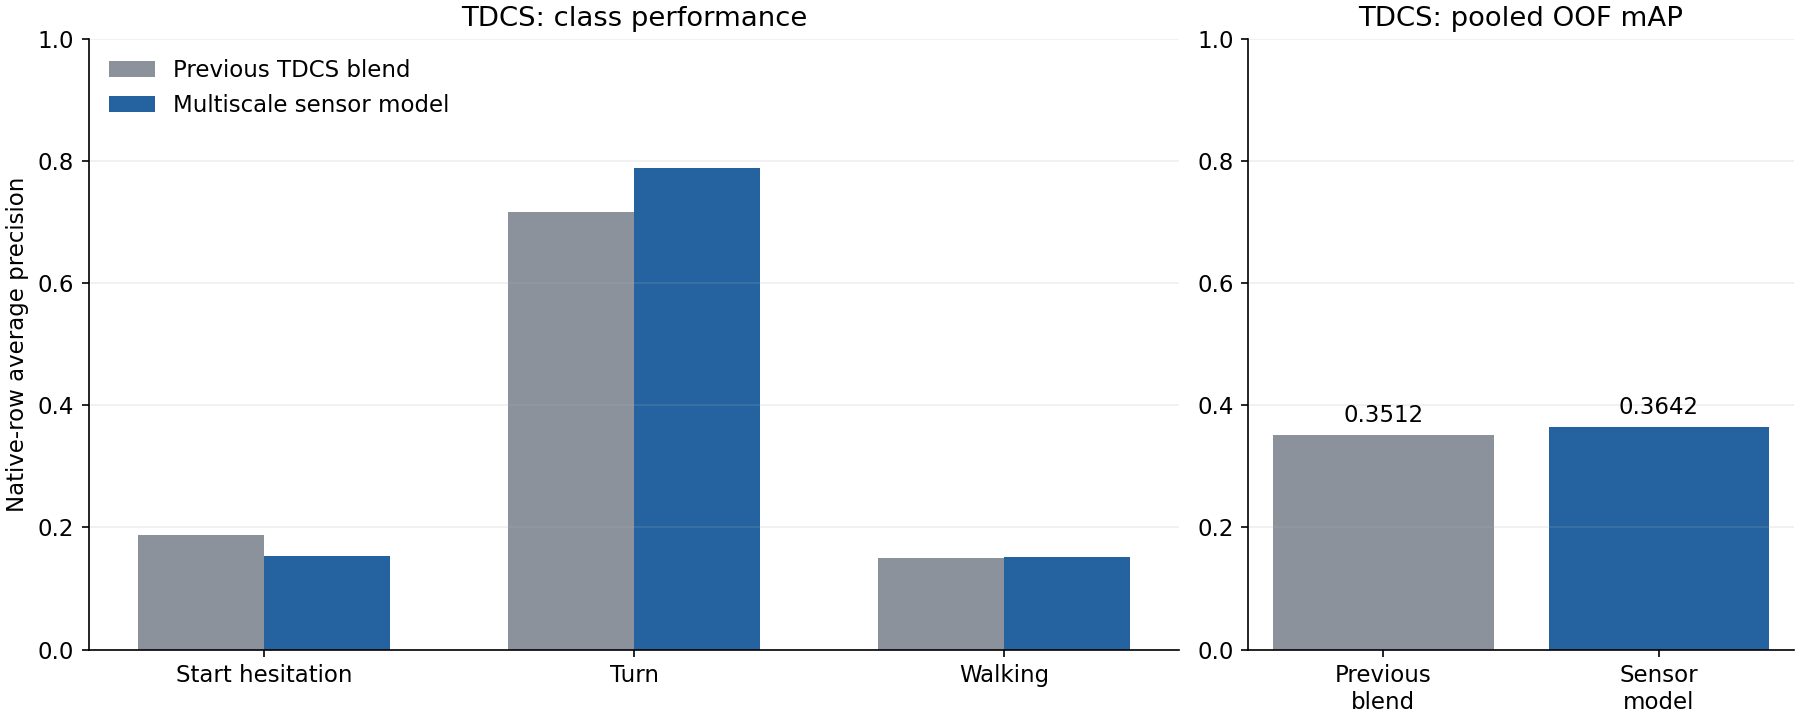

In [10]:
display(Image(filename=str(RESULT['figures'][0])))

### Examine held-out subject folds

In [11]:
display(RESULT['fold_metrics'].style.format({name: '{:.4f}' for name in [*TARGETS, 'mAP']}))

,fold,StartHesitation,Turn,Walking,mAP
0,0,0.3913,0.8446,0.1926,0.4762
1,1,0.0571,0.7658,0.1790,0.3340
2,2,0.1179,0.6656,0.0889,0.2908
3,3,0.1355,0.8217,0.0723,0.3432
4,4,0.1032,0.7969,0.0441,0.3147


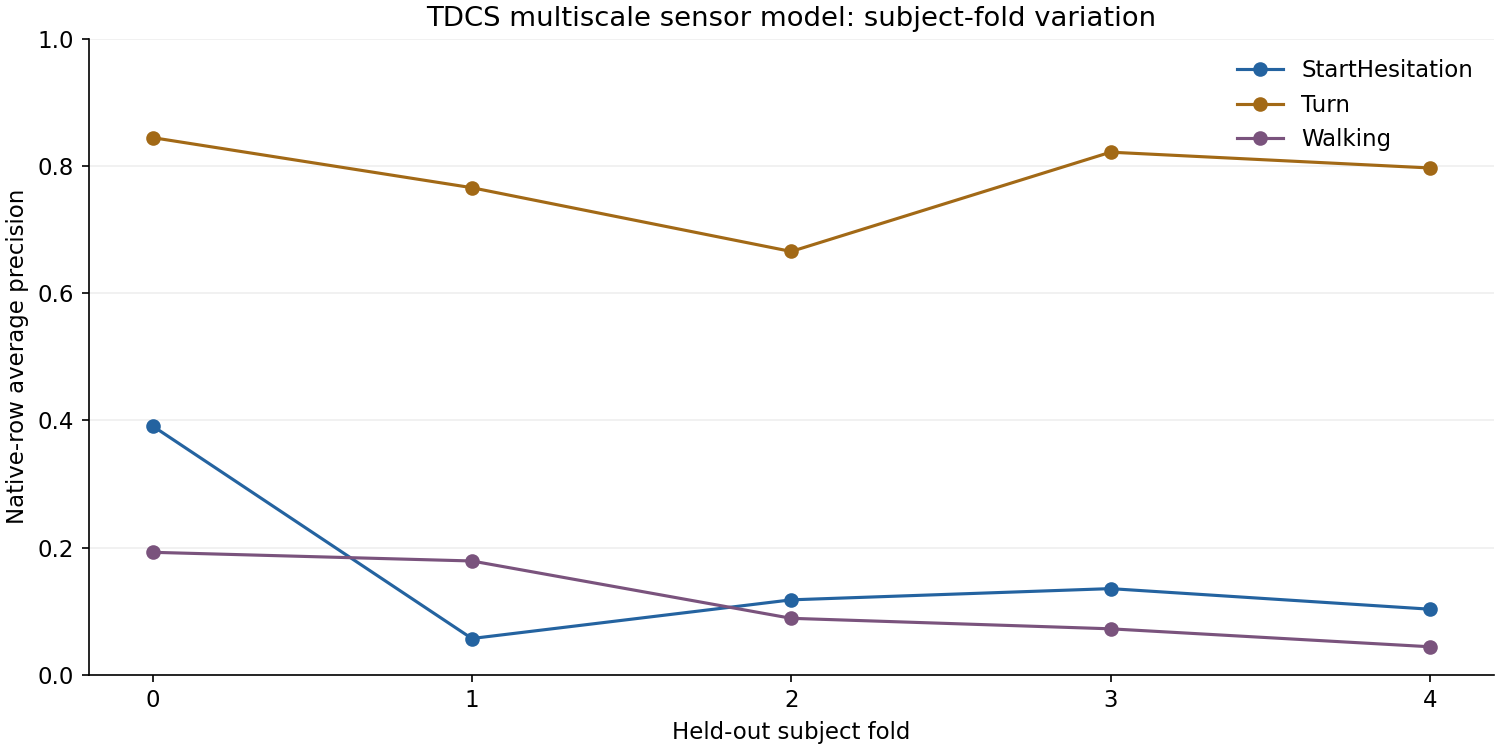

In [12]:
display(Image(filename=str(RESULT['figures'][1])))

## Takeaways

The decision below comes from the executed TDCS metrics. The DeFOG result
remains recorded separately at 0.817. A higher TDCS OOF score is evidence for
this experiment, not a guaranteed competition result.

In [13]:
candidate = RESULT['decision']['candidate_tdcs_oof_mAP']
baseline = RESULT['decision']['previous_tdcs_oof_mAP']
print(f'TDCS: {candidate:.4f} versus {baseline:.4f}; delta {candidate - baseline:+.4f}.')
print('Decision:', RESULT['decision']['decision'])
print('Retained DeFOG reported OOF mAP: 0.817')
print('No Kaggle submission was made by this notebook.')

TDCS: 0.3642 versus 0.3512; delta +0.0130.
Decision: retain as a separate candidate
Retained DeFOG reported OOF mAP: 0.817
No Kaggle submission was made by this notebook.
